In [108]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import glob
import json
import pretty_html_table

sns.set_context("talk")
pd.options.display.max_columns = None

RESULTS_FOLDER = "../results/movebank/"

In [84]:
csv_files = glob.glob("../results/movebank/metrics/*.csv")
full_df = pd.concat((pd.read_csv(f) for f in csv_files), ignore_index=True)

species_metadata = pd.read_csv("../data/movebank/metadata/species_metadata.csv")
full_df = pd.merge(full_df, species_metadata, on=["species"])
full_df["movement"] = pd.Categorical(full_df["movement"], ['WALK', 'FLY', 'SWIM'])

full_df["final_sizes_raw"] = full_df["final_sizes"]
full_df["final_sizes"] = full_df["final_sizes_raw"].map(eval)
def count_scales(r):
    if r["final_sizes"] is not None:
        return len(r["final_sizes"]) + 1
    if r["num_stops"] > 0:
        return 1
    return 0
full_df["num_scales"] = full_df.apply(count_scales, axis=1)

df_10 = full_df[full_df["downsample_rate_minutes"] == 10]
df = full_df[full_df["downsample_rate_minutes"] == 60].copy()
# df = df_60.copy()


In [85]:

df.columns

# df["Number of Scales"] = df["final_sizes"].map(lambda x: len(x) + 1)

Index(['Unnamed: 0_x', 'dataset', 'species', 'individual', 'stop_radius',
       'label_singleton', 'downsample_rate_minutes',
       'median_minutes_between_gps', 'mean_minutes_between_gps',
       'median_speed', 'mean_speed', 'num_gps_points', 'data_starts',
       'data_ends', 'days_spanned', 'max_speed', 'num_stops', 'num_scales',
       'final_sizes', 'final_size_2', 'final_size_3', 'final_size_4',
       'Unnamed: 0_y', 'locomotion', 'fly_detail', 'class', 'order', 'family',
       'genus', 'movement', 'common_name', 'median_body_length_cm',
       'final_sizes_raw'],
      dtype='object')

In [86]:
_df = df [
    # (df["median_minutes_between_gps"] <= 90) &
    (df["days_spanned"] >= 60) &
    # (df["num_scales"] >= 2) &
    # (df["num_stops"] >= 10) &
    True
]
print(f"{len(_df)}/{len(df)} animals")

print(len(_df["dataset"].unique()), "datasets")
print(len(_df["species"].unique()), "species")
print(len(_df["individual"].unique()), "individual animals")




for movement in df.movement.unique():
    m_df = _df[_df["movement"] == movement]
    print(f"**** {movement} *****")
    print(len(m_df["dataset"].unique()), "datasets")
    print(len(m_df["species"].unique()), "species")
    print(len(m_df["individual"].unique()), "individual animals")

3531/7773 animals
132 datasets
124 species
3375 individual animals
**** FLY *****
101 datasets
85 species
2308 individual animals
**** WALK *****
29 datasets
34 species
914 individual animals
**** SWIM *****
4 datasets
5 species
180 individual animals


4193/7773 animals


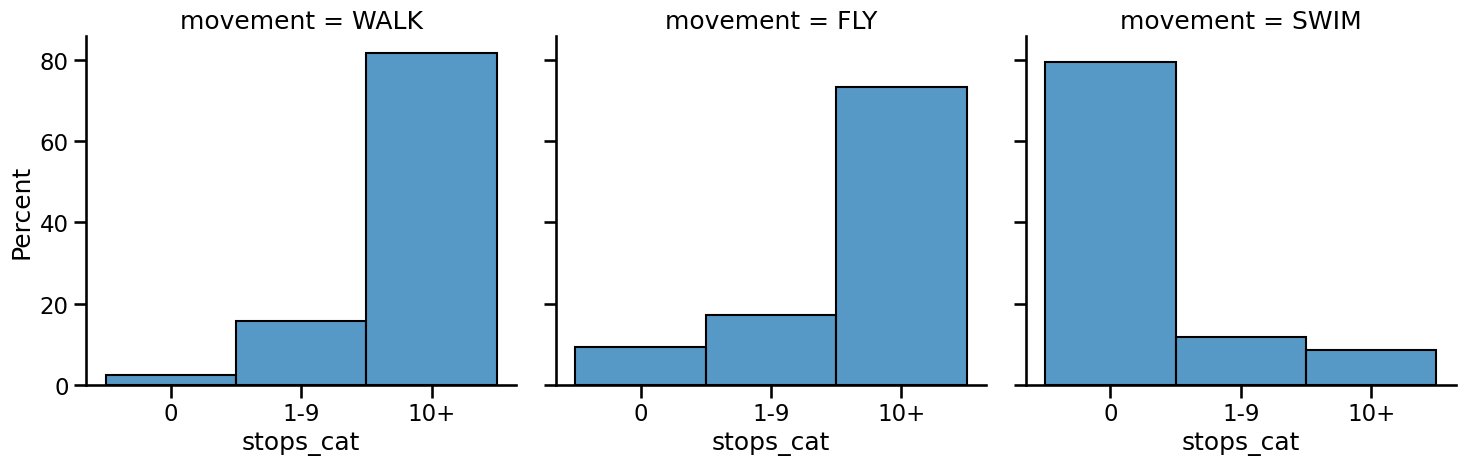

In [87]:
df["stops_cat"] = "0"
# for i in range(0, 10):
#     df.loc[df["num_stops"] >= i, "stops_cat"] = str(i)
# df.loc[df["num_stops"] >= 10, "stops_cat"] = "10+"
# df["stops_cat"] = pd.Categorical(df['stops_cat'], [str(i) for i in range(0, 10)] + ['10+'])


df.loc[df["num_stops"] >= 1, "stops_cat"] = "1-9"
df.loc[df["num_stops"] >= 20, "stops_cat"] = "10+"
df["stops_cat"] = pd.Categorical(df['stops_cat'], ["0", "1-9", '10+'])

df["no_stops"] = df.apply(lambda r: 1 if (r["stops_cat"] == "0") else 0, axis=1)
df["1_9_stops"] = df.apply(lambda r: 1 if (r["stops_cat"] == "1-9") else 0, axis=1)
df["10+_stops"] = df.apply(lambda r: 1 if (r["stops_cat"] == "10+") else 0, axis=1)
df["no_scales"] = df.apply(lambda r: 1 if (r["num_scales"] < 2) else 0, axis=1)
df["yes_scales"] = df.apply(lambda r: 1 if (r["num_scales"] >= 2) else 0, axis=1)

_df = df [
    # (df["median_minutes_between_gps"] <= 90) &
    (df["days_spanned"] >= 30) &
    # (df["num_scales"] >= 2) &
    # (df["num_stops"] >= 10) &
    True
]
print(f"{len(_df)}/{len(df)} animals")
sns.displot(data=_df, x="stops_cat", col="movement", stat="percent", common_norm=False)

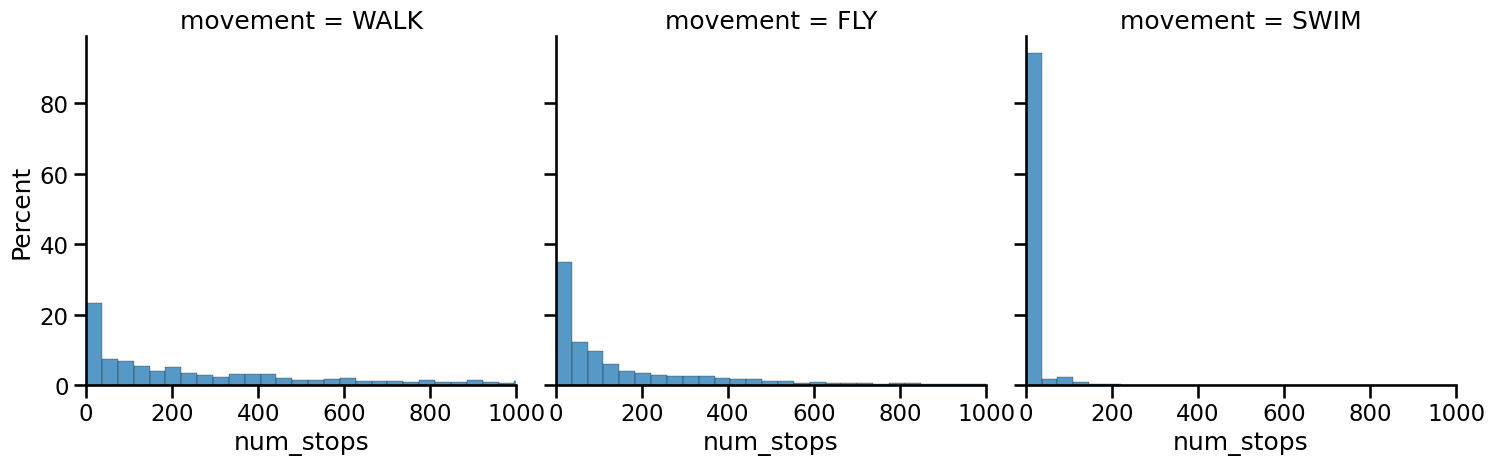

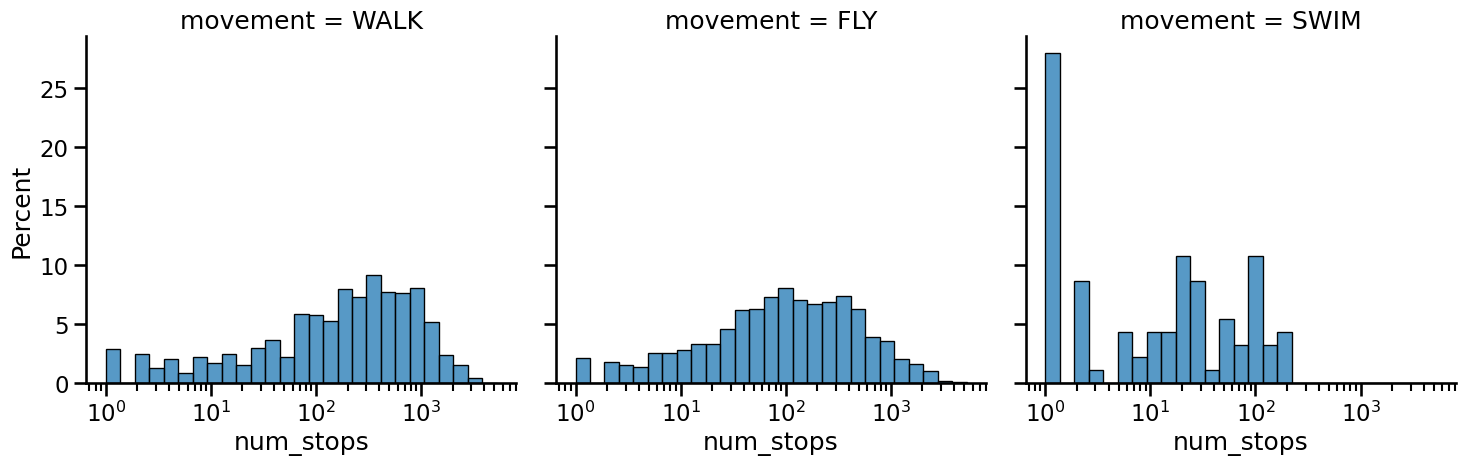

In [101]:
_df = df [
    # (df["median_minutes_between_gps"] <= 90) &
    (df["days_spanned"] >= 30) &
    # (df["num_scales"] >= 2) &
    # (df["num_stops"] >= 10) &
    True
]
p = sns.displot(data=_df, x="num_stops", col="movement", stat="percent", common_norm=False, log_scale=(False, False))
p.set(xlim=(0, 1000))
p = sns.displot(data=_df, x="num_stops", col="movement", stat="percent", common_norm=False, log_scale=(True, False))


4193/7773 animals


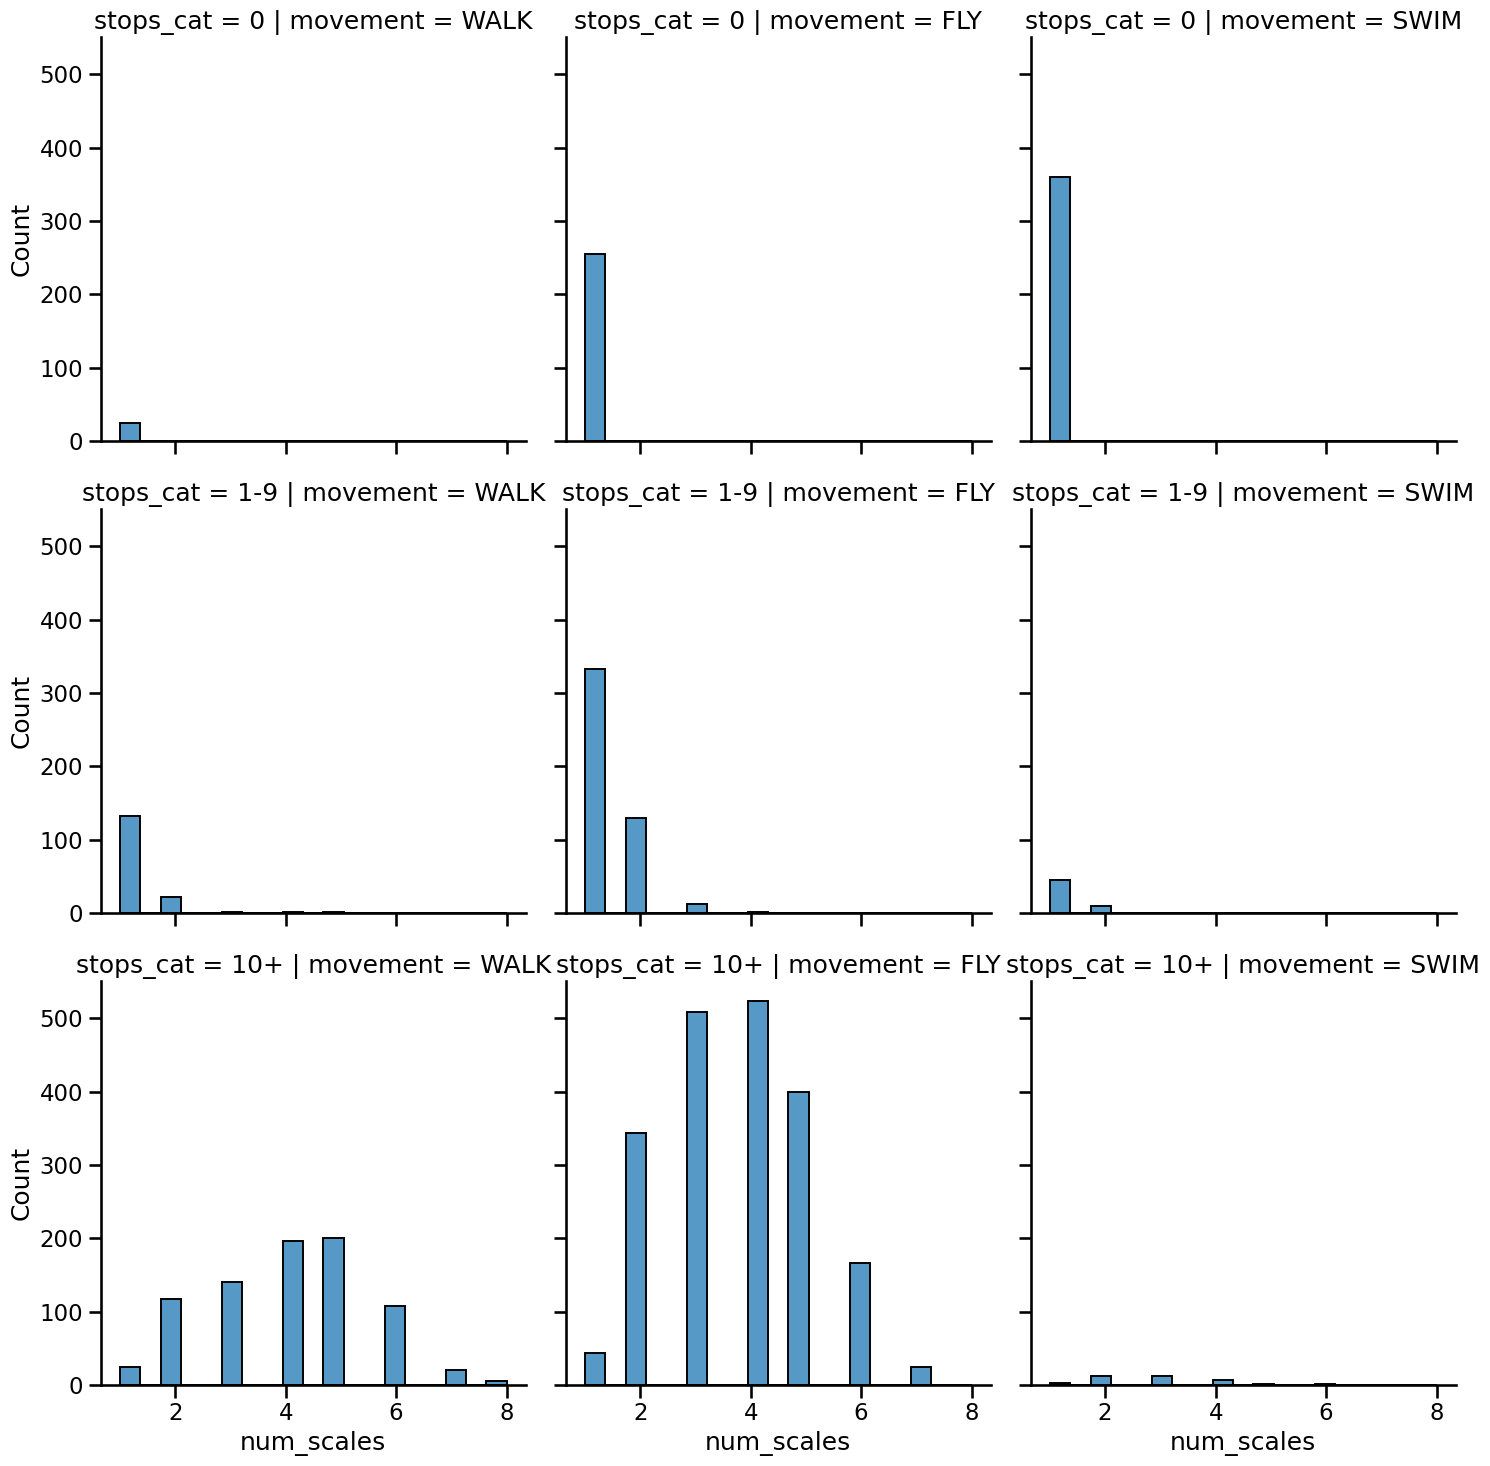

In [88]:
_df = df [
    # (df["median_minutes_between_gps"] <= 120) &
    (df["days_spanned"] >= 30) &
    # (df["num_scales"] >= 2)
    True
    ]

print(f"{len(_df)}/{len(df)} animals")

p = sns.displot(data=_df, x="num_scales", col="movement", row="stops_cat")

An individual animal needs 10+ stops to get any number of scales.

In [137]:
_df = df[
    df["days_spanned"] >= 60
]

species_summary = _df.groupby(["species", "common_name", "dataset"]).agg({
    # "common_name": "first",
    "movement": "first",
    "individual": "count",
    "median_speed": "median",
    "no_stops": "sum",
    "1_9_stops": "sum",
    "10+_stops": "sum",
    "no_scales": "sum",
    "yes_scales": "sum",
})
species_summary.to_csv(RESULTS_FOLDER + "species_summary.csv")

# with open(RESULTS_FOLDER + "species_summary.html", 'w') as f:
#     f.write(pretty_html_table.build_table(species_summary, 'blue_light', index=True))
    
species_summary.to_html(RESULTS_FOLDER + "species_summary.html")
species_summary
# TODO - join this on the larger movebank table to add the study name, add the citations by hand?

movement  \
species                common_name                 dataset               
Alces alces            Moose                       2548892515     WALK   
Anas penelope          Eurasian wigeon             1841261165      FLY   
Anas platyrhynchos     Mallard                     236953686       FLY   
                                                   1509697502      FLY   
Anser albifrons        Greater white-fronted goose 133992043       FLY   
...                                                                ...   
Tyto furcata           American Barn Owl           3578422072      FLY   
Ursus americanus       American black bear         2564825948     WALK   
Vanellus vanellus      Northern lapwing            1448409403      FLY   
Vulpes lagopus         Arctic fox                  1241071371     WALK   
Zalophus californianus California sea lion         259966228      SWIM   

                                                               individual  \
species                common_name                 dataset                  
Alces alces            Moose                       2548892515          24   
Anas penelope          Eurasian wigeon             1841261165          32   
Anas platyrhynchos     Mallard                     236953686           63   
                                                   1509697502          10   
Anser albifrons        Greater white-fronted goose 133992043           44   
...                                                                   ...   
Tyto furcata           American Barn Owl           3578422072           2   
Ursus americanus       American black bear         2564825948          21   
Vanellus vanellus      Northern lapwing            1448409403          12   
Vulpes lagopus         Arctic fox                  1241071371          32   
Zalophus californianus California sea lion         259966228           14   

                                                               median_speed  \
species                common_name                 dataset                    
Alces alces            Moose                       2548892515      0.003289   
Anas penelope          Eurasian wigeon             1841261165      0.010657   
Anas platyrhynchos     Mallard                     236953686       0.006646   
                                                   1509697502      0.014449   
Anser albifrons        Greater white-fronted goose 133992043       0.049652   
...                                                                     ...   
Tyto furcata           American Barn Owl           3578422072      0.020055   
Ursus americanus       American black bear         2564825948      0.007725   
Vanellus vanellus      Northern lapwing            1448409403      0.014303   
Vulpes lagopus         Arctic fox                  1241071371      0.164254   
Zalophus californianus California sea lion         259966228       0.284631   

                                                               no_stops  \
species                common_name                 dataset                
Alces alces            Moose                       2548892515         0   
Anas penelope          Eurasian wigeon             1841261165         0   
Anas platyrhynchos     Mallard                     236953686          0   
                                                   1509697502         0   
Anser albifrons        Greater white-fronted goose 133992043          1   
...                                                                 ...   
Tyto furcata           American Barn Owl           3578422072         0   
Ursus americanus       American black bear         2564825948         0   
Vanellus vanellus      Northern lapwing            1448409403         0   
Vulpes lagopus         Arctic fox                  1241071371         2   
Zalophus californianus California sea lion         259966228          0   

                                                               1_9_stops  \
species          

In [138]:
df["no_stops"] = df.apply(lambda r: 1 if (r["stops_cat"] == "0") else 0, axis=1)
df["1_9_stops"] = df.apply(lambda r: 1 if (r["stops_cat"] == "1-9") else 0, axis=1)
df["10+_stops"] = df.apply(lambda r: 1 if (r["stops_cat"] == "10+") else 0, axis=1)
df["no_scales"] = df.apply(lambda r: 1 if (r["num_scales"] < 2) else 0, axis=1)
df["yes_scales"] = df.apply(lambda r: 1 if (r["num_scales"] >= 2) else 0, axis=1)

_df = df[
    df["days_spanned"] >= 60
]


_df.groupby(["movement"]).agg({
    # "common_name": "first",
    # "movement": "first",
    "individual": "count",
    "no_stops": "sum",
    "1_9_stops": "sum",
    "no_scales": "sum",
    "yes_scales": "sum",
})

/var/folders/q_/ntb72mmd6jd72ljyc9qyw4100000gn/T/ipykernel_10001/195290488.py:12: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  _df.groupby(["movement"]).agg({


,individual,no_stops,1_9_stops,no_scales,yes_scales
movement,,,,,
WALK,922,23,123,146,776
FLY,2429,231,343,495,1934
SWIM,180,111,35,140,40


In [139]:
_df = df[
    df["days_spanned"] >= 60
]

_df.groupby(["movement", "stops_cat"]).agg({
    # "common_name": "first",
    # "movement": "first",
    # "species": lambda x: len(x.unique()),
    "individual": "count",
    # "no_stops": "sum",
    # "1_9_stops": "sum",
    "no_scales": "sum",
    "yes_scales": "sum",
})

/var/folders/q_/ntb72mmd6jd72ljyc9qyw4100000gn/T/ipykernel_10001/824398375.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  _df.groupby(["movement", "stops_cat"]).agg({


individual  no_scales  yes_scales
movement stops_cat                                   
WALK     0                  23         23           0
         1-9               123        104          19
         10+               776         19         757
FLY      0                 231        231           0
         1-9               343        237         106
         10+              1855         27        1828
SWIM     0                 111        111           0
         1-9                35         28           7
         10+                34          1          33